In [1]:
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/rl')

# RL on top of BC, cheaply (pick_place_cube)

Start from a policy that works sometimes, let it practise in the sim, keep what worked. Reward = the env's success flag at the end of an episode.

### step 0 — the starting policy: BC from `bc_policy.ipynb` (top + wrist, random shift, ~28%)


In [2]:
import os
from collections import Counter
from pathlib import Path

import numpy as np
import torch
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from torch import nn

from dream_robot.policies.bc.data import random_shift

REPO = Path.cwd().parent
dev = 'cuda'
cams = ['top', 'wrist']

In [3]:
@cache
def load_data():
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    state = np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32)
    action = np.asarray(ds.hf_dataset['action'], dtype=np.float32)
    episode = np.asarray(ds.hf_dataset['episode_index'])
    ims = {c: np.zeros((len(ds), 3, 128, 128), dtype=np.uint8) for c in cams}
    for i in range(len(ds)):
        item = ds[i]
        for c in cams:
            ims[c][i] = (np.asarray(item[f'observation.images.{c}']) * 255).round().astype(np.uint8)
    return state, action, episode, ims

load_data: cached, 1 call(s) stored


In [4]:
state, action, episode, ims = load_data()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same split as bc_policy
tr = ~np.isin(episode, val_eps)
print(f'{state.shape=}  train frames {tr.sum()}')

state.shape=(5288, 8)  train frames 4218


In [5]:
# the demo data, on the GPU; normalisation stays fixed from here on
IM = {c: torch.tensor(ims[c][tr]).to(dev) for c in cams}
ST = torch.tensor(state[tr]).to(dev)
AC = torch.tensor(action[tr]).to(dev)

s_mean, s_std = ST.mean(0), ST.std(0).clamp_min(1e-3)
a_mean, a_std = AC.mean(0), AC.std(0).clamp_min(1e-3)
im_stats = {}
for c in cams:
    sub = IM[c][::20].float() / 255
    im_stats[c] = (sub.mean((0, 2, 3)).reshape(1, 3, 1, 1), sub.std((0, 2, 3)).reshape(1, 3, 1, 1))

In [6]:
class SpatialSoftmax(nn.Module):
    def __init__(self, h, w):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))
        v, u = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing='ij')
        self.register_buffer('grid_u', u.reshape(-1))
        self.register_buffer('grid_v', v.reshape(-1))

    def forward(self, f):  # [B, C, H, W] -> [B, 2C]
        B, C, H, W = f.shape
        a = torch.softmax(f.reshape(B * C, H * W) / self.log_t.exp(), -1)
        return torch.stack([a @ self.grid_u, a @ self.grid_v], -1).reshape(B, C * 2)


def make_encoder():
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),
    )


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.encs = nn.ModuleDict({c: make_encoder() for c in cams})
        self.sss = nn.ModuleDict({c: SpatialSoftmax(16, 16) for c in cams})
        self.head = nn.Sequential(nn.Linear(128 * len(cams) + 8, 512), nn.ReLU(), nn.Linear(512, 8))

    def forward(self, ims, st):  # {cam: [B, 3, H, W] in [0, 1]}, [B, 8] -> [B, 8] in std units
        st = (st - s_mean) / s_std
        feats = [
            self.sss[c](self.encs[c]((ims[c] - im_stats[c][0]) / im_stats[c][1])) for c in cams
        ]
        return self.head(torch.cat(feats + [st], -1))

In [7]:
def train(net, IM, ST, AC, steps=3000, decay=False):
    # L1 in std units, random shift, as bc_policy step 10
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    # decay: lr follows a cosine from 1e-3 to 0, so the last steps barely move the weights
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps) if decay else None
    net.train()
    for step in range(steps + 1):
        i = torch.randint(0, len(ST), (64,), device=ST.device)  # data may sit on the CPU
        x = {c: random_shift(IM[c][i].to(dev).float() / 255, 4) for c in cams}
        loss = (net(x, ST[i].to(dev)) - (AC[i].to(dev) - a_mean) / a_std).abs().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if sched:
            sched.step()
        if step % 1000 == 0:
            print(f'{step:5d}  train {loss.item():.4f}')
    return {k: v.cpu() for k, v in net.state_dict().items()}  # weights on the CPU for the cache

In [8]:
@cache
def train_bc(seed=0):
    np.random.seed(seed)
    torch.manual_seed(seed)
    return train(Net().to(dev), IM, ST, AC)

train_bc: cached, 2 call(s) stored


In [9]:
seed = 1  # seed 0 got 1/20
bc = Net().to(dev)
bc.load_state_dict(train_bc(seed))
bc.eval();

    0  train 0.8245
 1000  train 0.0651
 2000  train 0.0492
 3000  train 0.0275


In [10]:
os.environ.setdefault('MUJOCO_GL', 'egl')
import logging

logging.disable(logging.WARNING)
import robosuite  # noqa: F401

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)

from dream_robot.core.registry import make_env

env = make_env('robosuite/pick_place_cube')


@torch.no_grad()
def act(net, obs):
    x = {
        c: torch.from_numpy(obs.images[c]).permute(2, 0, 1)[None].to(dev).float() / 255
        for c in cams
    }
    a = (net(x, torch.from_numpy(obs.state)[None].to(dev)) * a_std + a_mean)[0].cpu().numpy()
    a[7] = np.clip(a[7], 0.0, 1.0)
    return a


def rollout(net, seed):
    obs = env.reset(seed=seed)
    for step in range(600):
        r = env.step(act(net, obs))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


def evaluate(net, seeds=range(1000, 1020)):
    res = [rollout(net, s) for s in seeds]
    fails = Counter(m for ok, m, _ in res if not ok)
    print(f'{sum(ok for ok, _, _ in res)}/{len(res)}  failures {dict(fails)}')
    return res

In [11]:
@cache
def eval_bc(seed):  # seed: which trained bc this is, for the cache key
    return evaluate(bc)

eval_bc: cached, 1 call(s) stored


In [12]:
res_bc = eval_bc(seed)

6/20  failures {'no_grasp': 14}


### step 1 — practice: 100 new cube positions, keep the successful episodes

Seeds 2000+, never the eval seeds 1000–1019.


In [13]:
@cache
def practice(seed, seeds=range(2000, 2100)):  # seed: which trained bc plays
    wins, modes = [], []
    for s in seeds:
        obs = env.reset(seed=s)
        ep = {c: [] for c in cams} | {'state': [], 'action': []}
        for step in range(600):
            a = act(bc, obs)
            for c in cams:
                ep[c].append(obs.images[c].transpose(2, 0, 1))  # [3, H, W] uint8
            ep['state'].append(obs.state)
            ep['action'].append(a)
            r = env.step(a)
            obs = r.observation
            if r.terminated or r.truncated:
                break
        modes.append('success' if r.success else str(r.failure_mode))
        if r.success:
            wins.append({k: np.stack(v) for k, v in ep.items()})
    return wins, modes

practice: cached, 1 call(s) stored


In [14]:
wins, modes = practice(seed)
print(f'{len(wins)}/{len(modes)} succeeded  {dict(Counter(modes))}')
print('frames kept:', sum(len(w['action']) for w in wins), ' (demos: 4218)')

21/100 succeeded  {'no_grasp': 78, 'success': 21, 'wrong_target': 1}
frames kept: 5540  (demos: 4218)


### step 2 — learn from the successes: keep training bc on demos + its 21 wins, then eval


In [15]:
@cache
def finetune_round1(seed):
    IM2 = {
        c: torch.cat([IM[c], torch.tensor(np.concatenate([w[c] for w in wins])).to(dev)])
        for c in cams
    }
    ST2 = torch.cat([ST, torch.tensor(np.concatenate([w['state'] for w in wins])).to(dev)])
    AC2 = torch.cat([AC, torch.tensor(np.concatenate([w['action'] for w in wins])).to(dev)])
    np.random.seed(seed)
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(bc.state_dict())  # start from bc, not from scratch
    return train(net, IM2, ST2, AC2)

finetune_round1: cached, 1 call(s) stored


In [16]:
rl1 = Net().to(dev)
rl1.load_state_dict(finetune_round1(seed))
rl1.eval();

    0  train 0.0278
 1000  train 0.0275
 2000  train 0.0213
 3000  train 0.0248


In [17]:
@cache
def eval_rl1(seed):
    return evaluate(rl1)

eval_rl1: cached, 1 call(s) stored


In [18]:
res_rl1 = eval_rl1(seed)
print('bc was 6/20')

3/20  failures {'no_grasp': 16, 'dropped': 1}
bc was 6/20


### step 3 — 20 eval episodes can't tell 6 from 3; score both on 100 (seeds 1000–1099, ~5 min each)


In [19]:
nets = {'bc': bc, 'rl1': rl1}

In [20]:
@cache
def eval100(name, seed):
    return evaluate(nets[name], range(1000, 1100))

eval100: cached, 6 call(s) stored


In [21]:
for name in nets:
    print(name, end='  ')
    eval100(name, seed)

bc  23/100  failures {'no_grasp': 74, 'wrong_target': 3}
rl1  17/100  failures {'no_grasp': 78, 'dropped': 2, 'wrong_target': 3}


bc 23/100, rl1 17/100: round 1 bought nothing (gap ~1 std error, so maybe a small loss).

Why: bc is deterministic, so its 21 practice wins are positions it already solves. Copying them adds no new information about the 78 positions where it fails. Keeping successes only helps if practice sometimes succeeds where the policy usually fails, and that needs **exploration**.


### step 4 — round 2: practise with noise on every action, keep the wins, train, eval on 100

Noise = 0.2 × each action's std (arm ~0.01–0.04 rad). The wins keep the actions actually played, noise included.


In [22]:
@cache
def practice_noisy(seed, sigma=0.2, seeds=range(2000, 2100)):
    rng = np.random.default_rng(0)
    std = a_std.cpu().numpy()
    wins, modes = [], []
    for s in seeds:
        obs = env.reset(seed=s)
        ep = {c: [] for c in cams} | {'state': [], 'action': []}
        for step in range(600):
            a = act(bc, obs) + sigma * std * rng.standard_normal(8).astype(np.float32)
            a[7] = np.clip(a[7], 0.0, 1.0)
            for c in cams:
                ep[c].append(obs.images[c].transpose(2, 0, 1))
            ep['state'].append(obs.state)
            ep['action'].append(a)
            r = env.step(a)
            obs = r.observation
            if r.terminated or r.truncated:
                break
        modes.append('success' if r.success else str(r.failure_mode))
        if r.success:
            wins.append({k: np.stack(v) for k, v in ep.items()} | {'seed': s})
    return wins, modes

practice_noisy: cached, 1 call(s) stored


In [23]:
wins_n, modes_n = practice_noisy(seed)
new = sum(modes[w['seed'] - 2000] != 'success' for w in wins_n)
print(f'noisy: {len(wins_n)}/100 succeeded  {dict(Counter(modes_n))}')
print(f'wins on positions the noise-free run failed: {new}   (noise-free: {len(wins)}/100)')

noisy: 21/100 succeeded  {'no_grasp': 73, 'wrong_target': 4, 'success': 21, 'dropped': 2}
wins on positions the noise-free run failed: 13   (noise-free: 21/100)


In [24]:
@cache
def finetune_round2(seed):
    IM2 = {
        c: torch.cat([IM[c], torch.tensor(np.concatenate([w[c] for w in wins_n])).to(dev)])
        for c in cams
    }
    ST2 = torch.cat([ST, torch.tensor(np.concatenate([w['state'] for w in wins_n])).to(dev)])
    AC2 = torch.cat([AC, torch.tensor(np.concatenate([w['action'] for w in wins_n])).to(dev)])
    np.random.seed(seed)
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(bc.state_dict())
    return train(net, IM2, ST2, AC2)

finetune_round2: cached, 1 call(s) stored


In [25]:
rl2 = Net().to(dev)
rl2.load_state_dict(finetune_round2(seed))
rl2.eval()
nets['rl2'] = rl2
eval100('rl2', seed)
print('bc 23/100, rl1 17/100')

    0  train 0.0986
 1000  train 0.1154
 2000  train 0.1170
 3000  train 0.1001
54/100  failures {'no_grasp': 39, 'wrong_target': 4, 'dropped': 3}
bc 23/100, rl1 17/100


```-
                practice wins   new positions   eval (100 seeds)
bc              —               —               23/100
rl1 (no noise)  21/100          0               17/100
rl2 (noise 0.2) 21/100          13              54/100
```

Same number of wins; what changed is that 13 of them are positions bc fails on, and every noisy episode is slightly off bc's usual path. Train loss sits at ~0.10 (vs 0.025): the noise itself can't be fitted, only its average.


### step 5 — more rounds, one at a time

Round k: rl(k-1) practises with noise on 100 fresh positions; train rl(k-1) on demos + the wins of every round so far; eval on 100.


In [26]:
def play_noisy(net, seeds, sigma=0.2):
    # as practice_noisy, for any net
    rng = np.random.default_rng(0)
    std = a_std.cpu().numpy()
    wins, modes = [], []
    for s in seeds:
        obs = env.reset(seed=s)
        ep = {c: [] for c in cams} | {'state': [], 'action': []}
        for step in range(600):
            a = act(net, obs) + sigma * std * rng.standard_normal(8).astype(np.float32)
            a[7] = np.clip(a[7], 0.0, 1.0)
            for c in cams:
                ep[c].append(obs.images[c].transpose(2, 0, 1))
            ep['state'].append(obs.state)
            ep['action'].append(a)
            r = env.step(a)
            obs = r.observation
            if r.terminated or r.truncated:
                break
        modes.append('success' if r.success else str(r.failure_mode))
        if r.success:
            wins.append({k: np.stack(v) for k, v in ep.items()} | {'seed': s})
    return wins, modes


wins_by_round = {2: wins_n}

In [27]:
@cache
def practice_round(k, seed):
    first = 2000 + 100 * (k - 2)  # round 3 plays 2100-2199, round 4 2200-2299, ...
    return play_noisy(nets[f'rl{k - 1}'], range(first, first + 100))

practice_round: cached, 1 call(s) stored


In [28]:
@cache
def finetune_round(k, seed):
    pool = [w for j in range(2, k + 1) for w in wins_by_round[j]]
    # on the CPU: demos + every round's wins outgrow the 8 GB GPU; train moves each batch over
    IM2 = {
        c: torch.cat([IM[c].cpu(), torch.tensor(np.concatenate([w[c] for w in pool]))])
        for c in cams
    }
    ST2 = torch.cat([ST.cpu(), torch.tensor(np.concatenate([w['state'] for w in pool]))])
    AC2 = torch.cat([AC.cpu(), torch.tensor(np.concatenate([w['action'] for w in pool]))])
    np.random.seed(seed)
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(nets[f'rl{k - 1}'].state_dict())  # keep improving the last policy
    return train(net, IM2, ST2, AC2)

finetune_round: cached, 2 call(s) stored


In [29]:
def one_round(k):
    wins_by_round[k], modes_k = practice_round(k, seed)
    print(f'round {k} practice: {len(wins_by_round[k])}/100  {dict(Counter(modes_k))}')
    net = Net().to(dev)
    net.load_state_dict(finetune_round(k, seed))
    nets[f'rl{k}'] = net.eval()
    print(f'rl{k}', end='  ')
    eval100(f'rl{k}', seed)

In [30]:
one_round(3)
print('bc 23/100, rl2 54/100')

round 3 practice: 50/100  {'success': 50, 'no_grasp': 46, 'dropped': 2, 'wrong_target': 2}
    0  train 0.1447
 1000  train 0.1388
 2000  train 0.1590
 3000  train 0.1428
rl3  6/100  failures {'no_grasp': 94}
bc 23/100, rl2 54/100


rl3 6/100: collapsed. Two variants, each changing one thing vs rl3 (same data: demos + rounds 2 and 3 wins):

```-
            starts from   training seed
rl3         rl2           1
A rl3_s2    rl2           2
B rl3_bc    bc            1
```


In [31]:
@cache
def finetune_from_bc(k, seed):
    # as finetune_round, but starting from bc every time
    pool = [w for j in range(2, k + 1) for w in wins_by_round[j]]
    IM2 = {
        c: torch.cat([IM[c].cpu(), torch.tensor(np.concatenate([w[c] for w in pool]))])
        for c in cams
    }
    ST2 = torch.cat([ST.cpu(), torch.tensor(np.concatenate([w['state'] for w in pool]))])
    AC2 = torch.cat([AC.cpu(), torch.tensor(np.concatenate([w['action'] for w in pool]))])
    np.random.seed(seed)
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(bc.state_dict())
    return train(net, IM2, ST2, AC2)

finetune_from_bc: cached, 1 call(s) stored


In [32]:
for name, weights in [
    ('rl3_s2', lambda: finetune_round(3, 2)),
    ('rl3_bc', lambda: finetune_from_bc(3, seed)),
]:
    net = Net().to(dev)
    net.load_state_dict(weights())
    nets[name] = net.eval()
    print(name, end='  ')
    eval100(name, seed)
print('rl2 54/100, rl3 6/100')

    0  train 0.1325
 1000  train 0.1396
 2000  train 0.1429
 3000  train 0.1458
rl3_s2  39/100  failures {'no_grasp': 59, 'dropped': 2}
    0  train 0.1498
 1000  train 0.1368
 2000  train 0.1610
 3000  train 0.1436
rl3_bc  1/100  failures {'no_grasp': 89, 'wrong_target': 10}
rl2 54/100, rl3 6/100


```-
            starts from   seed   eval
rl3         rl2           1       6/100
A rl3_s2    rl2           2      39/100
B rl3_bc    bc            1       1/100
```

Starting from bc didn't save it (B 1/100), another seed did (A 39/100). With noisy labels the result swings 1 → 39 on the training seed alone, so one run per arm (rl2's 54 included) says little. Train loss never drops (~0.14) and lr stays at 1e-3, so the last step's weights are a random point along a noisy path.


### step 6 — lr decay: round 2's recipe again, lr cosine-decayed to 0 (same seed as rl2's 54/100)

In [35]:
@cache
def finetune_round2_decay(seed):
    # finetune_round2 with decay=True
    IM2 = {
        c: torch.cat([IM[c].cpu(), torch.tensor(np.concatenate([w[c] for w in wins_n]))])
        for c in cams
    }
    ST2 = torch.cat([ST.cpu(), torch.tensor(np.concatenate([w['state'] for w in wins_n]))])
    AC2 = torch.cat([AC.cpu(), torch.tensor(np.concatenate([w['action'] for w in wins_n]))])
    np.random.seed(seed)
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(bc.state_dict())
    return train(net, IM2, ST2, AC2, decay=True)

finetune_round2_decay: not cached, will compute


In [36]:
net = Net().to(dev)
net.load_state_dict(finetune_round2_decay(seed))
nets['rl2_cos'] = net.eval()
print('rl2_cos', end='  ')
eval100('rl2_cos', seed)
print('rl2 (constant lr) 54/100')

    0  train 0.1030
 1000  train 0.1184
 2000  train 0.1140
 3000  train 0.1023
rl2_cos  30/100  failures {'no_grasp': 66, 'wrong_target': 3, 'dropped': 1}
rl2 (constant lr) 54/100


rl2_cos 30/100 vs rl2 54/100, same seed and data. Train loss still ends at ~0.10: the noise in the labels sets that floor, decay can't lower it. So decay is no fix, and 54 may have been a lucky run.

### step 7 — REINFORCE: every episode counts, weighted by how it went

The policy is a Gaussian around the net's output μ(s) (std units), with the practice noise σ = 0.2:

```-
log π(a|s) = −‖a − μ(s)‖² / 2σ²  + const

gradient of expected success  ≈  mean over steps t of  A · ∇ log π(aₜ|sₜ)
A = R − b        R = 1 if the episode succeeded else 0,   b = mean R of the batch

loss = mean over steps of  A · ‖aₜ − μ(sₜ)‖² / 2σ²
```

So it is regression toward the played actions, weighted by A: pulled toward actions of successful episodes (A > 0), **pushed away** from those of failed ones (A < 0). Filtered BC was weight 1 on wins, 0 on failures.

Each round: the current net plays 100 noisy episodes on fresh seeds (3000+), every step's frames kept, 1 in 4 steps stored to fit in RAM; a few hundred gradient steps; eval on 100.

In [37]:
def play_all(net, seeds, sigma=0.2, every=4):
    # as play_noisy, but keeps every episode (wins and failures), 1 in `every` steps
    rng = np.random.default_rng(0)
    std = a_std.cpu().numpy()
    eps = []
    for s in seeds:
        obs = env.reset(seed=s)
        ep = {c: [] for c in cams} | {'state': [], 'action': []}
        for step in range(600):
            a = act(net, obs) + sigma * std * rng.standard_normal(8).astype(np.float32)
            a[7] = np.clip(a[7], 0.0, 1.0)
            if step % every == 0:
                for c in cams:
                    ep[c].append(obs.images[c].transpose(2, 0, 1))
                ep['state'].append(obs.state)
                ep['action'].append(a)
            r = env.step(a)
            obs = r.observation
            if r.terminated or r.truncated:
                break
        eps.append(
            {k: np.stack(v) for k, v in ep.items()}
            | {'R': float(r.success), 'mode': str(r.failure_mode)}
        )
    return eps


pg_nets = {0: bc}  # round k's net plays round k+1

In [38]:
@cache
def pg_collect(k, seed):
    first = 3000 + 100 * (k - 1)  # round 1 plays 3000-3099, round 2 3100-3199, ...
    return play_all(pg_nets[k - 1], range(first, first + 100))

pg_collect: not cached, will compute


In [39]:
@cache
def pg_update(k, seed, sigma=0.2, steps=300, lr=1e-4):
    eps = pg_collect(k, seed)
    b = np.mean([e['R'] for e in eps])  # baseline: this batch's success rate
    IMk = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STk = torch.tensor(np.concatenate([e['state'] for e in eps]))
    ACk = torch.tensor(np.concatenate([e['action'] for e in eps]))
    Ak = torch.tensor(
        np.concatenate([np.full(len(e['action']), e['R'] - b) for e in eps]), dtype=torch.float32
    )
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(pg_nets[k - 1].state_dict())
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        i = torch.randint(0, len(STk), (256,))
        x = {c: IMk[c][i].to(dev).float() / 255 for c in cams}
        mu = net(x, STk[i].to(dev))  # std units
        a = (ACk[i].to(dev) - a_mean) / a_std
        loss = (Ak[i].to(dev) * ((a - mu) ** 2).sum(-1) / (2 * sigma**2)).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 100 == 0:
            print(f'{step:4d}  loss {loss.item():+.3f}')
    return {k: v.cpu() for k, v in net.state_dict().items()}

pg_update: not cached, will compute


In [40]:
def pg_round(k):
    eps = pg_collect(k, seed)
    print(
        f'round {k} play: {sum(e["R"] for e in eps):.0f}/100  {dict(Counter(e["mode"] for e in eps))}'
    )
    net = Net().to(dev)
    net.load_state_dict(pg_update(k, seed))
    pg_nets[k] = nets[f'pg{k}'] = net.eval()
    print(f'pg{k}', end='  ')
    eval100(f'pg{k}', seed)

In [41]:
pg_round(1)
print('bc 23/100')

round 1 play: 28/100  {'dropped': 2, 'none': 28, 'no_grasp': 67, 'wrong_target': 3}
   0  loss -0.412
 100  loss -3808.112
 200  loss -133242.156
 300  loss -922202.250
pg1  0/100  failures {'no_grasp': 100}
bc 23/100


pg1 0/100: blew up, loss −0.4 → −922,202. With 72 failed episodes vs 28 won, most weight is A < 0, and "push away from that action" has no end: ‖a − μ‖² grows forever as μ runs off. The gradient is only right **at the policy that played** (there E[a − μ] = 0); 300 steps carried μ far from it, where the loss means nothing. Keeping the new policy near the one that collected the data is what PPO's clip is for.

### step 8 — PPO's clip: improve, but only near the policy that played

```-
r = π_new(a|s) / π_old(a|s) = exp( (‖a − μ_old‖² − ‖a − μ_new‖²) / 2σ² )

loss = − mean of  min( r·A,  clip(r, 1−ε, 1+ε)·A )        ε = 0.2
```

Once r leaves [0.8, 1.2] in the direction A wants, that sample's gradient is 0: no more reward for running further. Same data as pg1 (round 1, bc played).

In [42]:
@cache
def ppo_update(k, seed, sigma=0.2, clip=0.2, steps=300, lr=1e-4):
    eps = pg_collect(k, seed)
    b = np.mean([e['R'] for e in eps])
    IMk = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STk = torch.tensor(np.concatenate([e['state'] for e in eps]))
    ACk = torch.tensor(np.concatenate([e['action'] for e in eps]))
    Ak = torch.tensor(
        np.concatenate([np.full(len(e['action']), e['R'] - b) for e in eps]), dtype=torch.float32
    )
    torch.manual_seed(seed)
    old = pg_nets[k - 1]  # the policy that played, frozen
    net = Net().to(dev)
    net.load_state_dict(old.state_dict())
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        i = torch.randint(0, len(STk), (256,))
        x = {c: IMk[c][i].to(dev).float() / 255 for c in cams}
        s, a, A = STk[i].to(dev), (ACk[i].to(dev) - a_mean) / a_std, Ak[i].to(dev)
        with torch.no_grad():
            mu_old = old(x, s)
        mu = net(x, s)
        log_r = (((a - mu_old) ** 2).sum(-1) - ((a - mu) ** 2).sum(-1)) / (2 * sigma**2)
        r = log_r.clamp(-20, 20).exp()
        loss = -torch.min(r * A, r.clamp(1 - clip, 1 + clip) * A).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 100 == 0:
            out = ((r < 1 - clip) | (r > 1 + clip)).float().mean()
            print(f'{step:4d}  loss {loss.item():+.4f}  r outside clip {out:.0%}')
    return {k: v.cpu() for k, v in net.state_dict().items()}

ppo_update: not cached, will compute


In [43]:
def ppo_round(k, exam=True):  # exam=False: skip the 100-seed eval
    eps = pg_collect(k, seed)
    print(f'round {k} play: {sum(e["R"] for e in eps):.0f}/100')
    net = Net().to(dev)
    net.load_state_dict(ppo_update(k, seed))
    pg_nets[k] = nets[f'ppo{k}'] = net.eval()  # the next round's player
    if exam:
        print(f'ppo{k}', end='  ')
        eval100(f'ppo{k}', seed)

In [44]:
ppo_round(1)
print('bc 23/100, pg1 0/100')

round 1 play: 28/100
   0  loss +0.1238  r outside clip 0%
 100  loss +0.0899  r outside clip 27%
 200  loss +0.0842  r outside clip 35%
 300  loss +0.0812  r outside clip 33%
ppo1  25/100  failures {'no_grasp': 72, 'wrong_target': 1, 'dropped': 2}
bc 23/100, pg1 0/100


ppo1 25/100 (bc 23, pg1 0): the clip holds, a third of samples hit it and stop pulling, the policy stays sane. One step inside a small trust region moves it little; PPO gets its gains over many rounds.

### step 9 — more PPO rounds, one at a time; each round's play rate (noisy, fresh positions) is the curve

In [46]:
ppo_round(2, exam=False)
print('round 1 play: 28/100')

round 2 play: 35/100
   0  loss +0.0922  r outside clip 0%
 100  loss +0.1257  r outside clip 36%
 200  loss +0.1170  r outside clip 48%
 300  loss +0.1572  r outside clip 51%
round 1 play: 28/100


In [47]:
ppo_round(3, exam=False)
print('play: round 1 28/100, round 2 35/100')

round 3 play: 29/100
   0  loss +0.0986  r outside clip 0%
 100  loss +0.0522  r outside clip 60%
 200  loss +0.0579  r outside clip 66%
 300  loss +0.0752  r outside clip 58%
play: round 1 28/100, round 2 35/100


```-
round   played by   play (noisy, fresh seeds)   r outside clip at end
1       bc          28/100                      33%
2       ppo1        35/100                      51%
3       ppo2        29/100                      58%
```

Flat within noise (±4.5). Every step of an episode gets the same A, but a win and a no_grasp differ in a few steps near the cube out of ~400: 100 episodes of one bit each is a very weak signal.

### step 10 — a critic: which moves raised the odds

A second net reads the same frames and joints and outputs V(s) = P(this episode ends in success | s), trained with BCE on the episode's outcome R.

```-
A_t = V(s_t+1) − V(s_t)          a move is good if the odds went up after it
A_last = R − V(s_last)           the last step meets the real outcome
```

The critic trains on rounds before k and is read on round k, never on episodes it has seen: on its own training episodes it would just recognise the cube position and know R from frame one.

First the critic alone: trained on rounds 1–3 (300 episodes), checked on round 4 (ppo3 plays, fresh seeds 3300–3399).

In [48]:
class Critic(Net):
    def __init__(self):
        super().__init__()
        self.head = nn.Sequential(nn.Linear(128 * len(cams) + 8, 512), nn.ReLU(), nn.Linear(512, 1))

    def forward(self, ims, st):  # -> [B] logit of P(success)
        return super().forward(ims, st)[:, 0]

In [49]:
@cache
def train_critic(k, seed, steps=3000):
    # on every episode of rounds 1 .. k-1
    eps = [e for j in range(1, k) for e in pg_collect(j, seed)]
    IMc = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STc = torch.tensor(np.concatenate([e['state'] for e in eps]))
    Rc = torch.tensor(
        np.concatenate([np.full(len(e['action']), e['R']) for e in eps]), dtype=torch.float32
    )
    torch.manual_seed(seed)
    np.random.seed(seed)
    v = Critic().to(dev)
    opt = torch.optim.AdamW(v.parameters(), lr=1e-3)
    for step in range(steps + 1):
        i = torch.randint(0, len(STc), (64,))
        x = {c: random_shift(IMc[c][i].to(dev).float() / 255, 4) for c in cams}
        loss = F.binary_cross_entropy_with_logits(v(x, STc[i].to(dev)), Rc[i].to(dev))
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 1000 == 0:
            print(f'{step:5d}  bce {loss.item():.4f}')
    return {k: v.cpu() for k, v in v.state_dict().items()}

train_critic: not cached, will compute


round 4 play: 26/100
    0  bce 0.7098
 1000  bce 0.2006
 2000  bce 0.2484
 3000  bce 0.1713


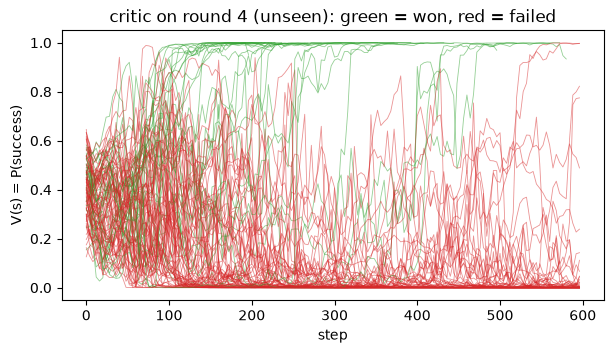

In [50]:
import matplotlib.pyplot as plt
import torch.nn.functional as F


@torch.no_grad()
def values(v, e):
    # [T] P(success) at every stored step of episode e
    x = {c: torch.tensor(e[c]).to(dev).float() / 255 for c in cams}
    return torch.sigmoid(v(x, torch.tensor(e['state']).to(dev))).cpu().numpy()


eps4 = pg_collect(4, seed)  # ppo3 plays; the critic never sees these
print(f'round 4 play: {sum(e["R"] for e in eps4):.0f}/100')
critic = Critic().to(dev)
critic.load_state_dict(train_critic(4, seed))
critic.eval()

fig, ax = plt.subplots(figsize=(7, 3.5))
for e in eps4:
    ax.plot(
        np.arange(len(e['action'])) * 4,
        values(critic, e),
        color='tab:green' if e['R'] else 'tab:red',
        lw=0.6,
        alpha=0.5,
    )
ax.set(
    xlabel='step',
    ylabel='V(s) = P(success)',
    title='critic on round 4 (unseen): green = won, red = failed',
)
plt.show()

On unseen episodes the critic works: everyone starts at ~0.3–0.5 (it can't know yet), wins jump to ~1 between steps ~100 and 250 (the grasp and lift), most failures sink to 0 after ~150. So A = V(s_t+1) − V(s_t) is large at those few moves and ~0 elsewhere, where episode-level A spread the credit over all ~400 steps. A few red lines climb to 1 late: episodes that looked like wins and then went wrong (dropped, wrong bin).

### step 11 — PPO with the critic's credit (actor-critic)

Same clipped update as step 8; only A changes: per step from the critic, then scaled to unit std across the batch.

In [51]:
def critic_advantages(v, eps):
    # per episode: A_t = V(s_t+1) - V(s_t), last step R - V(s_last); then / std over all steps
    A = []
    for e in eps:
        V = values(v, e)
        A.append(np.append(V[1:], e['R']) - V)
    A = np.concatenate(A)
    return (A / A.std()).astype(np.float32)


def ppo_steps(old, IMk, STk, ACk, Ak, seed, sigma=0.2, clip=0.2, steps=300, lr=1e-4):
    # step 8's clipped loop, for any advantages
    torch.manual_seed(seed)
    net = Net().to(dev)
    net.load_state_dict(old.state_dict())
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        i = torch.randint(0, len(STk), (256,))
        x = {c: IMk[c][i].to(dev).float() / 255 for c in cams}
        s, a, A = STk[i].to(dev), (ACk[i].to(dev) - a_mean) / a_std, Ak[i].to(dev)
        with torch.no_grad():
            mu_old = old(x, s)
        mu = net(x, s)
        log_r = (((a - mu_old) ** 2).sum(-1) - ((a - mu) ** 2).sum(-1)) / (2 * sigma**2)
        r = log_r.clamp(-20, 20).exp()
        loss = -torch.min(r * A, r.clamp(1 - clip, 1 + clip) * A).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 100 == 0:
            out = ((r < 1 - clip) | (r > 1 + clip)).float().mean()
            print(f'{step:4d}  loss {loss.item():+.4f}  r outside clip {out:.0%}')
    return {k: v.cpu() for k, v in net.state_dict().items()}

In [52]:
@cache
def ac_update(k, seed):
    eps = pg_collect(k, seed)
    v = Critic().to(dev)
    v.load_state_dict(train_critic(k, seed))  # trained on rounds before k only
    v.eval()
    Ak = torch.tensor(critic_advantages(v, eps))
    IMk = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STk = torch.tensor(np.concatenate([e['state'] for e in eps]))
    ACk = torch.tensor(np.concatenate([e['action'] for e in eps]))
    return ppo_steps(pg_nets[k - 1], IMk, STk, ACk, Ak, seed)

ac_update: not cached, will compute


In [53]:
def ac_round(k, exam=True):
    eps = pg_collect(k, seed)
    print(f'round {k} play: {sum(e["R"] for e in eps):.0f}/100')
    net = Net().to(dev)
    net.load_state_dict(ac_update(k, seed))
    pg_nets[k] = nets[f'ac{k}'] = net.eval()
    if exam:
        print(f'ac{k}', end='  ')
        eval100(f'ac{k}', seed)


ac_round(4)
print('bc 23/100, ppo1 25/100')

round 4 play: 26/100
    0  bce 0.7098
 1000  bce 0.2006
 2000  bce 0.2484
 3000  bce 0.1713
   0  loss -0.0100  r outside clip 0%
 100  loss -0.0477  r outside clip 53%
 200  loss +0.0341  r outside clip 52%
 300  loss +0.0448  r outside clip 47%
ac4  13/100  failures {'no_grasp': 82, 'wrong_target': 5}
bc 23/100, ppo1 25/100


ac4 13/100 (bc 23, ppo1 25; ppo3, the policy it started from, never examined). Clip hit by ~half the samples again. Suspect: the critic's lines jitter ±0.3 frame to frame during the approach (steps 0–150), so most per-move credit there is noise, and dividing by the std blows it up as much as the real jumps.

### step 12 — actor-critic from bc, on round 1's data: only the credit differs from pg1 (0/100) and ppo1 (25/100)

The critic trains on rounds 2–4 and is read on round 1.

In [54]:
@cache
def train_critic_except(k, seed, rounds=(1, 2, 3, 4), steps=3000):
    # train_critic on every listed round but k
    eps = [e for j in rounds if j != k for e in pg_collect(j, seed)]
    IMc = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STc = torch.tensor(np.concatenate([e['state'] for e in eps]))
    Rc = torch.tensor(
        np.concatenate([np.full(len(e['action']), e['R']) for e in eps]), dtype=torch.float32
    )
    torch.manual_seed(seed)
    np.random.seed(seed)
    v = Critic().to(dev)
    opt = torch.optim.AdamW(v.parameters(), lr=1e-3)
    for step in range(steps + 1):
        i = torch.randint(0, len(STc), (64,))
        x = {c: random_shift(IMc[c][i].to(dev).float() / 255, 4) for c in cams}
        loss = F.binary_cross_entropy_with_logits(v(x, STc[i].to(dev)), Rc[i].to(dev))
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 1000 == 0:
            print(f'{step:5d}  bce {loss.item():.4f}')
    return {k: v.cpu() for k, v in v.state_dict().items()}

train_critic_except: not cached, will compute


In [55]:
@cache
def ac_update_from_bc(seed):
    eps = pg_collect(1, seed)  # bc played
    v = Critic().to(dev)
    v.load_state_dict(train_critic_except(1, seed))
    v.eval()
    Ak = torch.tensor(critic_advantages(v, eps))
    IMk = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STk = torch.tensor(np.concatenate([e['state'] for e in eps]))
    ACk = torch.tensor(np.concatenate([e['action'] for e in eps]))
    return ppo_steps(bc, IMk, STk, ACk, Ak, seed)

ac_update_from_bc: not cached, will compute


In [56]:
net = Net().to(dev)
net.load_state_dict(ac_update_from_bc(seed))
nets['ac1'] = net.eval()
print('ac1', end='  ')
eval100('ac1', seed)
print('same data: pg1 0/100, ppo1 25/100;  bc 23/100')

    0  bce 0.7070
 1000  bce 0.3053
 2000  bce 0.1497
 3000  bce 0.2053
   0  loss +0.0179  r outside clip 0%
 100  loss +0.0534  r outside clip 54%
 200  loss +0.0226  r outside clip 58%
 300  loss -0.1395  r outside clip 55%
ac1  30/100  failures {'no_grasp': 62, 'dropped': 6, 'wrong_target': 2}
same data: pg1 0/100, ppo1 25/100;  bc 23/100


```-
same data (round 1, bc played), same start (bc), 300 steps
credit                          eval
whole episode, no clip  pg1      0/100
whole episode, clip     ppo1    25/100
critic per move, clip   ac1     30/100       bc: 23/100
```

Best of the three, but +7 over bc is ~1.5 std errors: a hint. ~55% of samples outside the clip: the update is pushing as far as allowed.

### step 13 — smaller moves: fewer steps, or a lower lr (same data, critic and start as ac1)

In [57]:
@cache
def ac_from_bc(seed, steps, lr):
    # ac_update_from_bc with steps and lr exposed
    eps = pg_collect(1, seed)
    v = Critic().to(dev)
    v.load_state_dict(train_critic_except(1, seed))
    v.eval()
    Ak = torch.tensor(critic_advantages(v, eps))
    IMk = {c: torch.tensor(np.concatenate([e[c] for e in eps])) for c in cams}
    STk = torch.tensor(np.concatenate([e['state'] for e in eps]))
    ACk = torch.tensor(np.concatenate([e['action'] for e in eps]))
    return ppo_steps(bc, IMk, STk, ACk, Ak, seed, steps=steps, lr=lr)

ac_from_bc: not cached, will compute


In [58]:
for name, steps, lr in [('ac1_100steps', 100, 1e-4), ('ac1_lr3e-5', 300, 3e-5)]:
    net = Net().to(dev)
    net.load_state_dict(ac_from_bc(seed, steps, lr))
    nets[name] = net.eval()
    print(name, end='  ')
    eval100(name, seed)
print('ac1 (300 steps, lr 1e-4) 30/100;  bc 23/100')

    0  bce 0.7070
 1000  bce 0.3053
 2000  bce 0.1497
 3000  bce 0.2053
   0  loss +0.0179  r outside clip 0%
 100  loss +0.0567  r outside clip 54%
ac1_100steps  24/100  failures {'no_grasp': 71, 'dropped': 3, 'wrong_target': 2}
    0  bce 0.7070
 1000  bce 0.3053
 2000  bce 0.1497
 3000  bce 0.2053
   0  loss +0.0179  r outside clip 0%
 100  loss +0.0486  r outside clip 33%
 200  loss -0.0104  r outside clip 45%
 300  loss -0.1501  r outside clip 46%
ac1_lr3e-5  25/100  failures {'no_grasp': 69, 'dropped': 4, 'wrong_target': 2}
ac1 (300 steps, lr 1e-4) 30/100;  bc 23/100


```-
                         steps   lr      clip-out at end   eval
ac1                      300     1e-4    55%               30/100
ac1_100steps             100     1e-4    54%               24/100
ac1_lr3e-5               300     3e-5    46%               25/100
```

All three within noise of bc's 23. The clip-out share barely drops with 3× smaller moves: with σ = 0.2 a tiny shift of μ already changes r a lot (log r moves by about (a − μ)·δ / σ²), so here a high share does **not** mean the behaviour changed much.

### step 14 — what RL buys, where it fails

Starting policy: BC (top + wrist, random shift), 20 demos, pick_place_cube. Reward = success at episode end, nothing else. 100 practice episodes per round (~6 min), eval on 100 unseen seeds.

```-
method (one round from bc unless noted)        eval /100
bc                                              23
keep wins, no noise                             17
keep wins, noise 0.2          (2 runs)          54, 30   (lr decay)
keep wins, noise, 2nd round   (3 runs)          6, 39, 1
REINFORCE, whole-episode credit                  0   (blew up)
PPO clip, whole-episode credit                  25
actor-critic (critic per-move credit) + clip    30, 24, 25
```

**What it buys**

- **A policy that improves without new demos.** Noisy practice + keep the wins took 23 → 30–54 for ~10 min of sim and no human.
- **Exploration is the lever.** Without noise the wins are positions it already solves (17/100, nothing learnt); with noise 13 of 21 wins were on positions it used to fail.
- **A working critic from one bit.** Trained on 300 episodes, it sees the outcome coming on unseen episodes: wins jump to ~1 at the grasp, misses sink to 0 by step ~150.

**Where it fails**

- **Huge run-to-run swings.** Same recipe, different training seed: 54 vs 30, 39 vs 1. One run per arm misleads; a claim needs 3 seeds × 100 episodes.
- **Policy gradient is starved at this budget.** One bit per ~400-step episode, 100 episodes per round: REINFORCE blows up, PPO and actor-critic stay within noise of the start.
- **Rounds don't stack.** Keep-wins round 3 collapsed (6/100); PPO's play rate stayed flat over 3 rounds (28, 35, 29).
- **Self-imitation copies its own wobble.** Noisy labels set a loss floor (~0.10 vs 0.025 on demos); lr decay doesn't help (30/100).

**What would fix each**

- 3 seeds per arm → the swings (cheap, just time)
- thousands of episodes per round, many parallel sims → policy gradient's starvation
- a denser reward (grasped, lifted, over the bin) → one bit per episode
- chunked actions (ACT) as the starting policy → fewer, larger decisions, so credit lands on fewer moves
- a smoothed critic (GAE) → jittery per-move credit